# COGS 109 Checkpoint 2 | Group comparison
Run this after the three member notebooks. It reads their saved results from `reports/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

methods = ['forward', 'elasticnet', 'lasso']
results = pd.concat([pd.read_csv(f'reports/{m}_results.csv') for m in methods], ignore_index=True)
results

,member,method,n_predictors,predictors,cv_error,aic,bic,accuracy,auc,precision,recall,tp,fp,tn,fn,baseline
0,Thomas Ton,Forward stepwise selection,11,"skipped_drills, agility_sec, ncaa_ppg, height_...",0.410740,825.573455,878.652419,0.636364,0.665542,0.647887,0.597403,46,25,52,31,0.5
1,Riley Ramos,Elastic net logistic regression,23,"height_in, weight_lb, wingspan_in, standing_re...",0.433491,842.893324,949.051251,0.649351,0.689492,0.653333,0.636364,49,26,51,28,0.5
2,Ishaan Tibdewal,Lasso logistic regression,3,"agility_sec, ncaa_ppg, skipped_drills",0.428547,836.680195,854.373183,0.623377,0.658627,0.650794,0.532468,41,22,55,36,0.5


## Binary outcome
1 = averaged more than the training median NBA PPG in the first three post-combine seasons, 0 = at or below it.

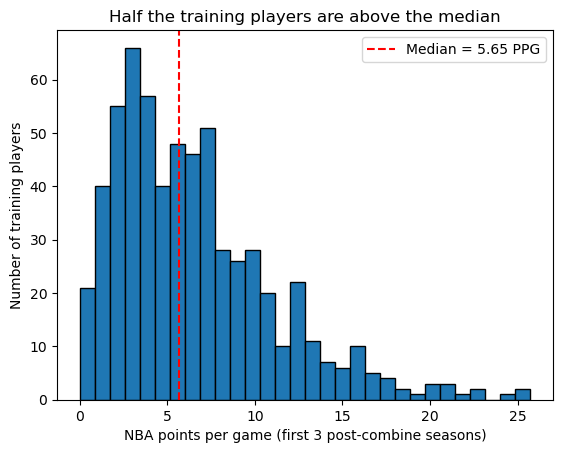

In [2]:
# outcome histogram with the threshold (training set only)
features = pd.read_csv('../data/predraft_features.csv')
outcomes = pd.read_csv('../data/nba_outcomes.csv')
df = features.merge(outcomes[['player_id', 'ppg_3yr']], on='player_id')
df = df[df.ncaa_match_status == 'matched'].reset_index(drop=True)
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42, stratify=df.position_group)
train = df.loc[train_idx]
threshold = train.ppg_3yr.median()

plt.hist(train.ppg_3yr, bins=30, edgecolor='black')
plt.axvline(threshold, color='red', linestyle='--', label=f'Median = {threshold:.2f} PPG')
plt.xlabel('NBA points per game (first 3 post-combine seasons)')
plt.ylabel('Number of training players')
plt.title('Half the training players are above the median')
plt.legend()
plt.savefig('reports/group_outcome_threshold.png', dpi=150)
plt.show()

## Workflow
- Split: 80/20, `random_state=42`, stratified by position (same 616/154 players as Checkpoint 1).
- Folds: 5-fold stratified CV on the training set, `random_state=42`, shared by everyone.
- Predictors: 24 (21 quantitative; position as 2 dummies with baseline Guard; `skipped_drills`).
- Methods: Thomas = forward stepwise, Riley = elastic net, Ishaan = lasso (1-SE rule).

## Model comparison

In [3]:
columns = ['method', 'n_predictors', 'cv_error', 'aic', 'bic', 'accuracy', 'auc',
           'precision', 'recall', 'tp', 'fp', 'tn', 'fn']
table = results.round(3).set_index('member')[columns].T
table['Baseline'] = ['Always predict majority', 0, '', '', '', results.baseline[0], 0.5,
                     '', '', '', '', '', '']
table.to_csv('reports/group_comparison.csv')
table

member,Thomas Ton,Riley Ramos,Ishaan Tibdewal,Baseline
method,Forward stepwise selection,Elastic net logistic regression,Lasso logistic regression,Always predict majority
n_predictors,11,23,3,0
cv_error,0.411,0.433,0.429,
aic,825.573,842.893,836.68,
bic,878.652,949.051,854.373,
accuracy,0.636,0.649,0.623,0.5
auc,0.666,0.689,0.659,0.5
precision,0.648,0.653,0.651,
recall,0.597,0.636,0.532,
tp,46,49,41,


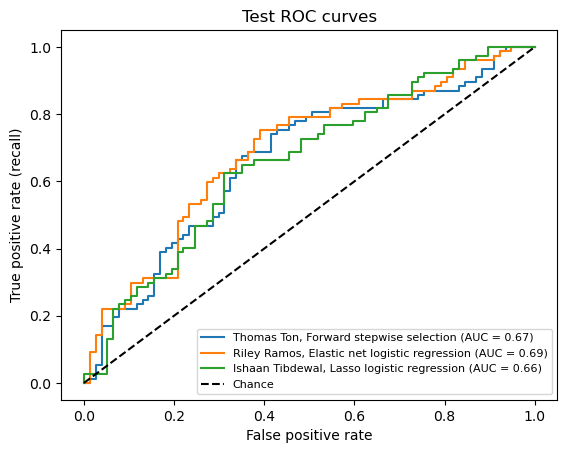

In [4]:
for i, m in enumerate(methods):
    roc = pd.read_csv(f'reports/{m}_roc.csv')
    row = results.iloc[i]   # results are in the same order as methods
    plt.plot(roc.fpr, roc.tpr, label=f'{row.member}, {row.method} (AUC = {row.auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('Test ROC curves')
plt.legend(fontsize=8)
plt.savefig('reports/group_roc.png', dpi=150)
plt.show()

In [5]:
# which predictors did each method keep?
kept = {}
for _, row in results.iterrows():
    kept[row.member] = row.predictors.split(', ')

all_predictors = []
for preds in kept.values():
    for p in preds:
        if p not in all_predictors:
            all_predictors.append(p)

kept_table = pd.DataFrame(index=all_predictors)
for member, preds in kept.items():
    kept_table[member] = ['x' if p in preds else '' for p in all_predictors]
kept_table

,Thomas Ton,Riley Ramos,Ishaan Tibdewal
skipped_drills,x,x,x
agility_sec,x,x,x
ncaa_ppg,x,x,x
height_in,x,x,
wingspan_in,x,x,
sprint_sec,x,x,
bench_reps,x,x,
ncaa_3p_pct,x,x,
ncaa_spg,x,x,
weight_lb,x,x,


**TODO (group):** Which model predicts best on the test set and why? Did the methods agree on which predictors matter? Did AIC, BIC and CV point to the same model?